# Notebook 3: Interpretability

**Project 3, Movie Genre Classification, Team KIA**

Notebook 2 measured how well each model scores. This notebook looks at what the models actually learned. Everything here uses the **TF-IDF logistic regression** models, one per selected genre (Crime, Action, Comedy). We use TF-IDF because each of its features is one word, so every coefficient and every SHAP value can be read as "this word pushed the prediction up or down". The embedding model's 384 dimensions have no such meaning.

The notebook has four parts:
1. **Setup**: rebuild the Notebook 2 test set and load the saved vectorizer, scaler and models.
2. **Coefficients**: the words each model weights most heavily, toward and away from its genre.
3. **SHAP**: how much each word actually contributes to predictions on the test set, compared with the coefficient ranking.
4. **Individual predictions**: waterfall plots for one confident correct prediction and the worst mistakes.

## 1. Setup

All paths are relative to this notebook's folder. `mpst_imdb_movies.csv` sits in the same folder as the notebooks, and `models/` (written by Notebook 2) is a subfolder of it. The CSV itself is not committed to the repo.

`MIN_VOTES` and `GENRES` must match Notebooks 1 and 2 exactly. Any other vote filter would rebuild a different test set, and the models would be explained on movies they were never scored on.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.metrics import f1_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 90)

CSV_PATH = Path("mpst_imdb_movies.csv")              # same folder as the notebooks
MODELS_DIR = Path("models")                          # written by Notebook 2

MIN_VOTES = 100                                     # vote filter chosen in Notebook 1
GENRES = ["Crime", "Action", "Comedy"]              # selected genres from Notebook 2
SHAP_GENRE = "Crime"                                # genre explained with SHAP in sections 3-4

We load the CSV and apply the same vote filter as Notebooks 1 and 2. Then we rebuild both halves of the Notebook 2 split from the `split` column: training = `train` + `val`, test = `test`. The test set is what we explain. The training set is used only to compute the SHAP baseline in section 3 (the average training movie), and no model is refit on it. The row counts should match Notebook 2 (9,365 training, 2,330 test).

In [2]:
df = pd.read_csv(CSV_PATH)
df = df[df["numVotes"] >= MIN_VOTES]

train_df = df[df["split"].isin(["train", "val"])].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print(f"Vote filter: numVotes >= {MIN_VOTES}")
print(f"Training rows (train+val): {len(train_df)}")
print(f"Test rows:                 {len(test_df)}")

Vote filter: numVotes >= 100
Training rows (train+val): 9365
Test rows:                 2330


Next we load the fitted `TfidfVectorizer`, its `StandardScaler`, and the three logistic regression models that Notebook 2 saved. We transform the text with the vectorizer and scaler **exactly as fitted**, with no refitting, because the coefficients only make sense on features built the same way.

As a check that the right artifacts were loaded, we re-score each model on the test set. The macro-F1 values should match the TF-IDF rows of the Notebook 2 leaderboard.

In [3]:
tfidf = joblib.load(MODELS_DIR / "P3_N2_tfidf_vectorizer.pkl")
tfidf_scaler = joblib.load(MODELS_DIR / "P3_N2_tfidf_scaler.pkl")
models = {g: joblib.load(MODELS_DIR / f"P3_N2_tfidf_logreg_{g.lower()}.pkl") for g in GENRES}

vocab = tfidf.get_feature_names_out()
x_test_raw = tfidf.transform(test_df["plot_synopsis"])     # raw TF-IDF weights (for display)
x_test = tfidf_scaler.transform(x_test_raw)                 # scaled features the models expect

pd.DataFrame({
    "class_weight": [str(models[g].class_weight) for g in GENRES],
    "test macro-F1": [round(f1_score(test_df[g], models[g].predict(x_test), average="macro"), 4)
                      for g in GENRES],
}, index=GENRES)

,class_weight,test macro-F1
Crime,balanced,0.7519
Action,balanced,0.7867
Comedy,balanced,0.7377


## 2. Coefficients

Each model is a logistic regression, so its prediction is a weighted sum of word features: a positive coefficient pushes a synopsis **toward** the genre and a negative one pushes it **away**. Notebook 2 standardized every TF-IDF column (dividing by its standard deviation), so a coefficient means "change in log-odds per one standard deviation of that word". That puts all words on the same scale, so coefficient sizes can be compared across words.

For each genre we plot the 10 most positive coefficients (green) and the 10 most negative (red).

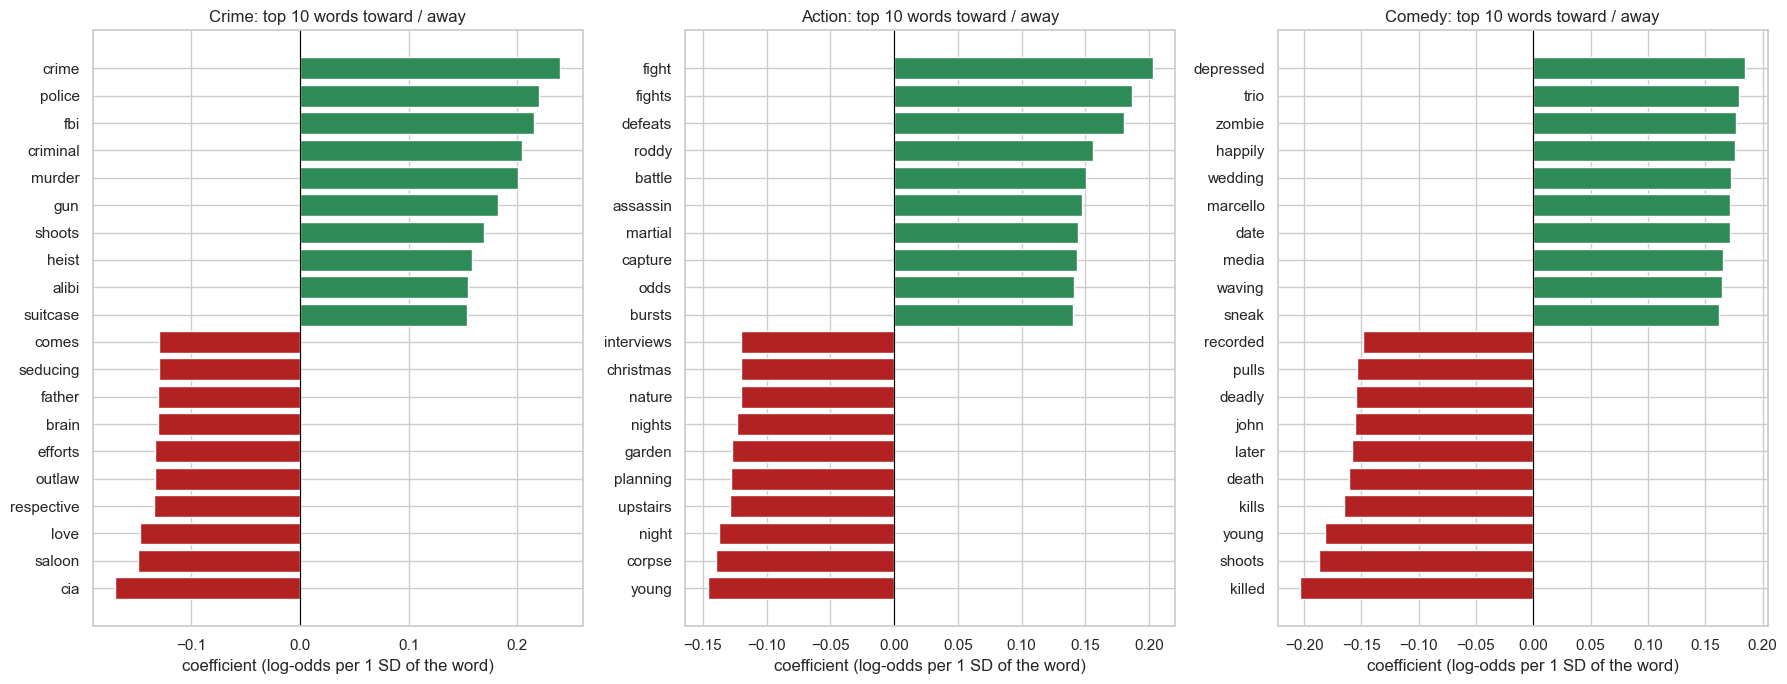

In [4]:
def top_coefficients(model, n=10):
    coefs = pd.Series(model.coef_.ravel(), index=vocab).sort_values()
    return pd.concat([coefs.head(n), coefs.tail(n)])

fig, axes = plt.subplots(1, len(GENRES), figsize=(18, 7))
for ax, g in zip(axes, GENRES):
    top = top_coefficients(models[g])
    colors = ["firebrick" if c < 0 else "seagreen" for c in top]
    ax.barh(top.index, top.values, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{g}: top 10 words toward / away")
    ax.set_xlabel("coefficient (log-odds per 1 SD of the word)")
plt.tight_layout()
plt.show()

**What the coefficients show**

- **Crime** has the most literal vocabulary. Its top words are *crime, police, fbi, criminal, murder, gun, shoots, heist, alibi*. The negative side shows which neighbouring genres the model separates Crime from: *cia* (spy stories, which IMDB files as Action/Thriller), *saloon* and *outlaw* (Westerns: lawbreaking, but a different genre), and *love, seducing, father* (romance and family drama).
- **Action** rewards combat and pursuit: *fight, fights, defeats, battle, assassin, martial, capture*. Its negative words (*corpse, night, upstairs, garden, christmas*) describe slower, domestic or horror-style settings.
- **Comedy** is defined mostly by what it lacks. Its strongest negative words are all about violence and death (*killed, shoots, kills, death, deadly*), which fits the Notebook 1 observation that "you can make a comedy out of anything". Its positive words are light social situations (*wedding, date, happily, trio*), plus *zombie*, which comes from the zombie-comedy subgenre.
- **Character names leak in.** *roddy* (Action) and *marcello* (Comedy) are not genre words. They are names that recur across a handful of training movies (sequels, remakes, or an actor's recurring role) that happen to share a genre. The model memorized them, and they will not generalize to new films. Section 4 shows a name driving a real mistake.

## 3. SHAP (Crime)

We explain the Crime model with `shap.LinearExplainer`, the exact explainer for linear models. For a linear model, a word's SHAP value on one movie is

$$\text{SHAP}_{word} = \text{coef}_{word} \times (x_{word} - \overline{x}_{word})$$

where $\overline{x}_{word}$ is the word's average value over the **training set**. That average is the baseline: the "typical movie" each prediction is compared against. We pass the training mean as a single background row, so the baseline uses all 9,365 training movies instead of a random subsample. SHAP values are in **log-odds**, the same units as the coefficients, and for each movie they add up exactly to (model output − baseline output).

We picked Crime because it had the clearest genre vocabulary in Notebook 1's term analysis, which makes it the easiest model to sanity-check.

The SHAP values are computed on the scaled features the model uses. For the plots we attach the **raw** TF-IDF weights as the displayed feature values, because a raw weight (0 = word absent) is easier to read than a standardized value. This changes only the labels and colors, not the SHAP values.

In [5]:
shap_model = models[SHAP_GENRE]

x_train_scaled = tfidf_scaler.transform(tfidf.transform(train_df["plot_synopsis"]))
train_mean = np.asarray(x_train_scaled.mean(axis=0))        # shape (1, n_words): the baseline movie

explainer = shap.LinearExplainer(shap_model, train_mean)
shap_values = explainer.shap_values(x_test.toarray())
base_value = float(np.ravel(explainer.expected_value)[0])

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(len(test_df), base_value),
    data=x_test_raw.toarray().astype(np.float32),
    feature_names=list(vocab),
)

# SHAP is exact for linear models: baseline + sum of SHAP values must equal the model's log-odds
assert np.allclose(base_value + shap_values.sum(axis=1), shap_model.decision_function(x_test))
print(f"SHAP matrix: {shap_values.shape}  |  baseline log-odds: {base_value:.3f}")

SHAP matrix: (2330, 10000)  |  baseline log-odds: -4.882


### 3a. Mean |SHAP| per word

The bar plot ranks words by their average absolute SHAP value over the 2,330 test movies. It shows how much each word moves predictions *in practice*, not how heavy its weight is.

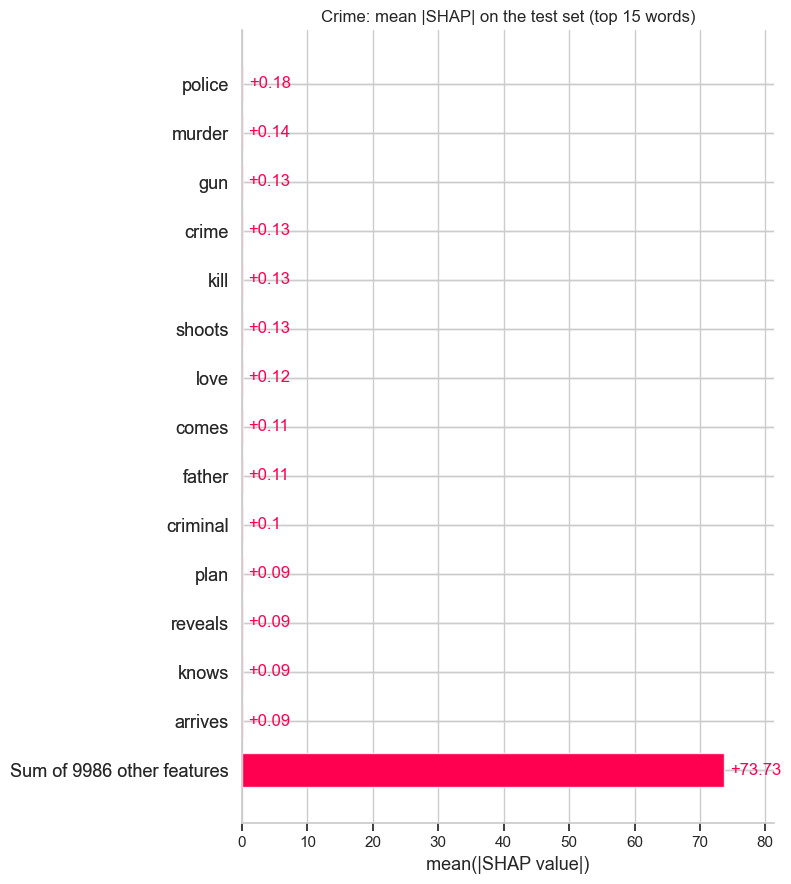

In [6]:
shap.plots.bar(explanation, max_display=15, show=False)
plt.title(f"{SHAP_GENRE}: mean |SHAP| on the test set (top 15 words)")
plt.tight_layout()
plt.show()

To compare this ranking with the coefficient ranking, the table lists the top 15 words by mean |SHAP| next to their coefficient rank (by absolute size, out of 10,000 words). It also shows the share of test synopses that contain each word. The second table goes the other way: the 10 largest coefficients and where they land in the SHAP ranking.

In [7]:
coef = pd.Series(shap_model.coef_.ravel(), index=vocab)
doc_freq = pd.Series(np.asarray((x_test_raw > 0).mean(axis=0)).ravel(), index=vocab)
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=vocab)

ranks = pd.DataFrame({
    "mean |SHAP|": mean_abs_shap.round(4),
    "SHAP rank": mean_abs_shap.rank(ascending=False).astype(int),
    "coef": coef.round(3),
    "|coef| rank": coef.abs().rank(ascending=False).astype(int),
    "% of test synopses": (100 * doc_freq).round(1),
})

print("Top 15 by mean |SHAP|:")
display(ranks.sort_values("SHAP rank").head(15))
print("Top 10 by |coefficient|:")
display(ranks.sort_values("|coef| rank").head(10))

Top 15 by mean |SHAP|:


,mean |SHAP|,SHAP rank,coef,|coef| rank,% of test synopses
police,0.1834,1,0.220,2,33.1
murder,0.1372,2,0.200,5,17.3
gun,0.1314,3,0.182,6,20.3
crime,0.1284,4,0.240,1,9.4
kill,0.1279,5,0.148,16,37.2
shoots,0.1262,6,0.170,8,20.9
love,0.1225,7,-0.147,17,34.7
comes,0.1143,8,-0.130,33,36.3
father,0.1077,9,-0.131,31,38.5
criminal,0.0958,10,0.204,4,6.4


Top 10 by |coefficient|:


,mean |SHAP|,SHAP rank,coef,|coef| rank,% of test synopses
crime,0.1284,4,0.240,1,9.4
police,0.1834,1,0.220,2,33.1
fbi,0.0706,28,0.216,3,3.2
criminal,0.0958,10,0.204,4,6.4
murder,0.1372,2,0.200,5,17.3
gun,0.1314,3,0.182,6,20.3
cia,0.0472,85,-0.170,7,2.4
shoots,0.1262,6,0.170,8,20.9
heist,0.0329,237,0.159,9,1.4
alibi,0.0264,412,0.154,10,1.0


**How the rankings differ, and why**

Both rankings start the same way: *police, murder, gun, crime, shoots* are near the top of each. Below that core they diverge, and **document frequency** explains the difference:

- **Common words climb.** *kill* (coefficient rank 16) is 5th by SHAP, *love* goes from 17th to 7th, *comes* from 33rd to 8th, and *reveals* from 116th to 12th. Each appears in roughly 30–38% of test synopses. Their weights are modest, but they move hundreds of predictions.
- **Rare words fall.** *heist* (coefficient rank 9) drops to 237th by SHAP, *alibi* (10th) to 412th, *cia* (7th) to 85th and *fbi* (3rd) to 28th. Each appears in only 1–3% of synopses. Their weights are large, but for the other 97–99% of movies they contribute almost nothing.

A linear model's SHAP value for a word is its coefficient times how far the movie sits from the average movie on that word. A rare word sits at zero for almost every movie, and its average is close to zero, so the product is tiny almost everywhere. The coefficient plot shows what the model *would* do if a word appeared. The SHAP bar plot shows what it actually does across real synopses.

### 3b. Beeswarm

Each dot is one test movie. Its horizontal position is that word's SHAP value for the movie, and its color is the word's TF-IDF weight in the synopsis (blue = absent or low, red = high).

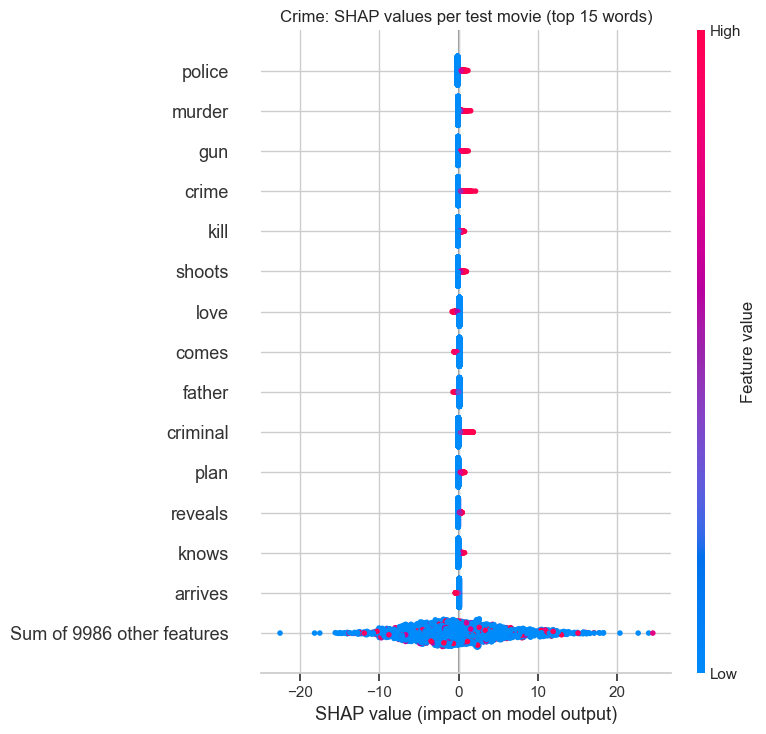

In [8]:
shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.title(f"{SHAP_GENRE}: SHAP values per test movie (top 15 words)")
plt.tight_layout()
plt.show()

**What the beeswarm shows that the bar plot hides**

The bar plot collapses each word to one unsigned number. The beeswarm keeps three things that number hides:

1. **Direction.** *police, murder, gun* put their red (present) dots on the right, pushing toward Crime. *love, father, comes* put their red dots on the left, pushing away. The bar plot ranks *love* 7th without showing that it argues *against* Crime.
2. **Absence counts too.** Each row splits into a blue band (synopses without the word) and a red spread (synopses with it). For common words the blue band sits slightly off zero, too little to see at this plot's scale but measurable. When *police* is missing, a movie loses about 0.14 log-odds relative to the average movie, and that happens to two thirds of the test set. When *love* is missing, a movie gains about 0.09. Much of a common word's mean |SHAP| comes from its absence, not its presence.
3. **Shape of the effect.** Words with similar mean |SHAP| can get there in very different ways. *police* moves almost every movie a little (−0.14 absent, +0.28 present on average). Rare words such as *alibi* or *fbi* do nothing for most movies but add up to 3–4 log-odds to the few that contain them. Only the per-movie spread shows that difference.
4. **No single word dominates.** The bottom row, "Sum of 9986 other features", spreads from about −20 to +25 log-odds, while each of the 14 named words moves a prediction by at most a few log-odds. The model's decisions come from the combined weight of the whole vocabulary, not from a handful of keywords. The waterfalls in section 4 show the same thing for individual movies.

## 4. Individual predictions

Waterfall plots break one movie's prediction into word contributions. Each one starts from the baseline E[f(x)], the average log-odds over training movies, adds each word's SHAP value, and ends at that movie's log-odds f(x). Positive log-odds means the model predicts Crime (probability above 0.5). The plot shows the 11 largest contributions individually and groups the remaining words into one "other features" bar.

We rank movies by **log-odds** rather than probability. These models are very confident: about two thirds of test movies get a probability above 0.99 or below 0.01, so many movies tie at a rounded probability of 1.0 or 0.0, and log-odds still separates them.

We pick three test movies for the Crime model:
- **Confidently right**: the true Crime movie with the highest predicted probability.
- **Worst false positive**: the non-Crime movie the model was most sure *was* Crime.
- **Worst false negative**: the Crime movie the model was most sure was *not* Crime.

Titles are shown here only for our own analysis. The model never saw them.

In [9]:
y_true = test_df[SHAP_GENRE].to_numpy()
log_odds = shap_model.decision_function(x_test)
pred = (log_odds > 0).astype(int)

picks = {
    "confidently right": np.where(y_true == 1, log_odds, -np.inf).argmax(),
    "worst false positive": np.where((y_true == 0) & (pred == 1), log_odds, -np.inf).argmax(),
    "worst false negative": np.where((y_true == 1) & (pred == 0), -log_odds, -np.inf).argmax(),
}

genre_cols = df.columns[df.columns.get_loc("numVotes") + 1:]     # the 0/1 genre dummies
pd.DataFrame([{
    "case": case,
    "title": f"{test_df.loc[i, 'primaryTitle']} ({int(test_df.loc[i, 'startYear'])})",
    "IMDB genres": ", ".join(g for g in genre_cols if test_df.loc[i, g] == 1),
    "log-odds": round(log_odds[i], 1),
    "synopsis begins": test_df.loc[i, "plot_synopsis"][:90] + "…",
} for case, i in picks.items()]).set_index("case")

,title,IMDB genres,log-odds,synopsis begins
case,,,,
confidently right,Payback (1999),"Action, Crime, Drama",20.7,Note: This is a synopsis of the threatrical release of PAYBACK. There is also a Direct...
worst false positive,Crime Zone (1988),"Action, Adventure, Fantasy",14.2,"In the fictional country Soleil, a brutal police state at war with Frodan, the governm..."
worst false negative,Moonshine County Express (1977),"Action, Comedy, Crime",-15.2,A man (Geoffrey Rush) wanders through a heavy rainstorm finding his way into a restaur...


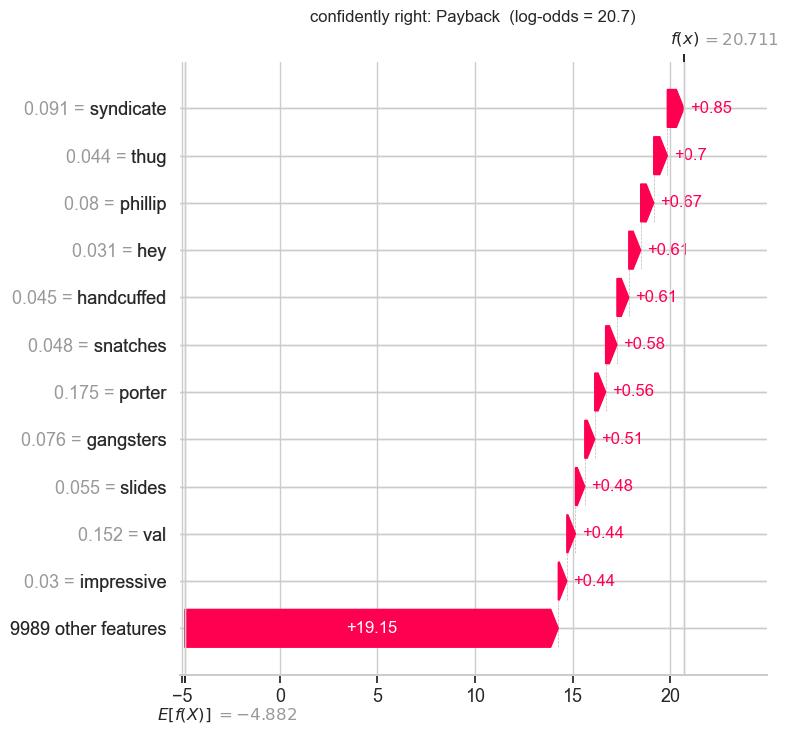

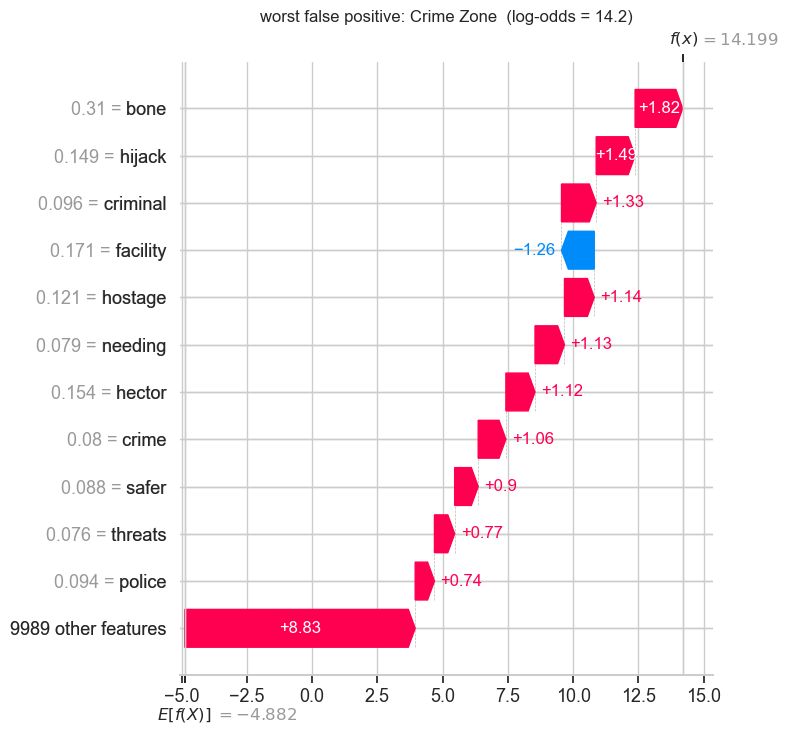

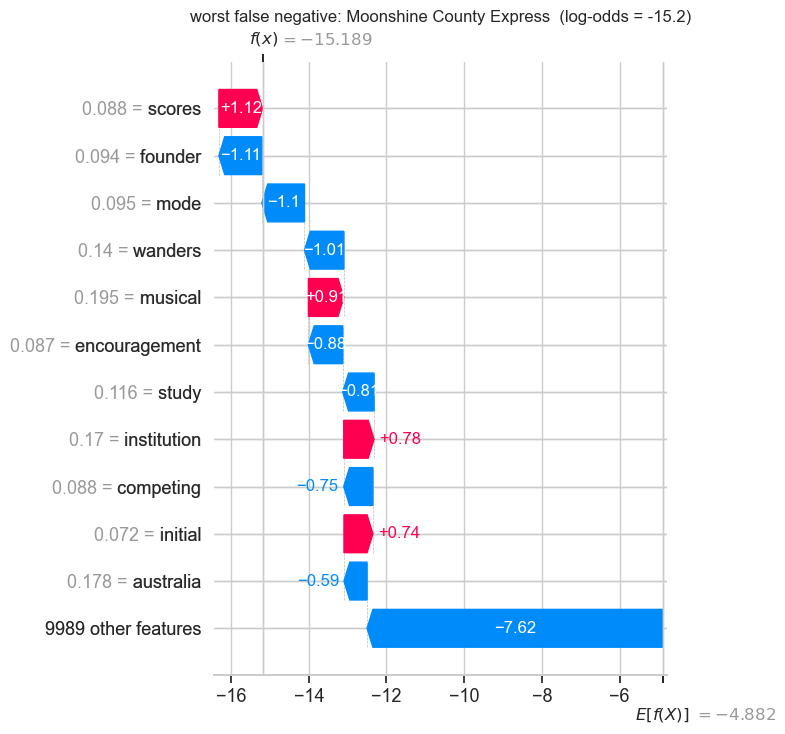

In [10]:
for case, i in picks.items():
    shap.plots.waterfall(explanation[i], max_display=12, show=False)
    plt.title(f"{case}: {test_df.loc[i, 'primaryTitle']}  (log-odds = {log_odds[i]:.1f})")
    plt.tight_layout()
    plt.show()

**Reading the three waterfalls**

- **Confidently right: *Payback* (1999), log-odds ≈ +20.7.** No single word decides this one. The largest contributions (*syndicate, thug, handcuffed, gangsters, snatches*) are each worth less than one log-odd, and the 11 words shown add up to only about +6. The other +19.15 comes from the "other features" bar: hundreds of small crime-flavored words. Three of the top 11 (*phillip, porter, val*) are character names, not crime vocabulary, an early sign of the name leakage that causes the next error. This synopsis is unusually long (about 31,000 characters and 964 distinct vocabulary words, against a median of about 200), so the evidence keeps stacking up. The model is confident because the whole text reads like a crime story, not because of a few keywords.
- **Worst false positive: *Crime Zone* (1988), log-odds ≈ +14.2.** IMDB lists it as Action, Adventure and Fantasy, but the synopsis is about a criminal in a police state, a hijacking and hostages, so *criminal, crime, hostage, hijack, police* all push toward Crime, and arguably the model reads the plot correctly. The single largest push, though, is *bone* (+1.8), followed by *hector* (+1.1). Those are character names, not crime vocabulary. The model learned them from training movies where characters with those names appeared in crime stories. This is the name leakage noted in section 2, causing a real error.
- **Worst false negative: *Moonshine County Express* (1977), log-odds ≈ −15.2.** IMDB labels it Crime, Action and Comedy, but its synopsis is about a pianist, with no crime vocabulary at all. Its largest contributions are music and study words. A few push slightly toward Crime (*scores* +1.12, *musical* +0.91), more push away (*founder, mode, wanders, encouragement, study*), and the rest of the vocabulary adds −7.62. That is because **the synopsis belongs to a different film**: it is word-for-word the synopsis of *Shine* (1996), Geoffrey Rush's biopic of pianist David Helfgott, which is also in the training set. The model is right about the text. The error is in the source data's pairing of synopsis and title.

Two lessons follow. The model is a word-counter: it succeeds when a genre shows up in the vocabulary and is fooled by memorized names. And its worst "mistakes" are partly data problems, either a debatable genre label or a synopsis attached to the wrong movie. In the Notebook 2 leaderboard, those count against the model even though it read the text correctly.

## Conclusions

- **The TF-IDF models learned readable vocabularies.** Crime follows police and the justice system, Action follows combat and pursuit, and Comedy is defined largely by the *absence* of violence and death.
- **Some features are memorized character names** (*roddy, marcello, bone, hector*). They help on the training data but do not generalize, and one of them drives the worst Crime false positive.
- **Coefficients and SHAP answer different questions.** Coefficients show what a word would do. SHAP shows what words actually do on real synopses. Document frequency explains the gap: frequent words with modest weights (*kill, love, comes*) outrank rare words with large weights (*heist, alibi, cia*) once you look at real predictions.
- **Confident predictions come from many small contributions, not one keyword**, and the model's worst errors trace back to its inputs: a plot that reads like a crime story but is labeled otherwise, and a synopsis attached to the wrong movie in the source data.